# Part 2 — Logistic Regression from Scratch: Book Bestseller Classification

**Purpose:** Explore a large open book-product dataset with PySpark and build a binary Logistic Regression classifier whose optimisation is implemented from scratch with NumPy.

## Dataset choice and target definition

- **Dataset:** Amazon product metadata, Books category, collected by McAuley Lab / UCSD.
- **Dataset source page:** https://mcauleylab.ucsd.edu/public_datasets/data/amazon/datasets.html
- **Direct dataset file:** https://snap.stanford.edu/data/amazon/productGraph/categoryFiles/meta_Books.json.gz
- **Expected scale:** approximately 2.37 million book/product metadata records (the source page reports 2,370,585 products).
- **Target proxy:** `is_bestseller = 1` for books with a valid Amazon Books sales rank at or above the top 10% by rank (i.e., rank is at or below the 10th percentile threshold); `0` for other books with a valid Books sales rank.

**Important limitation:** Amazon sales rank is a proxy for relative sales performance, not an official publisher or New York Times bestseller designation. The label is defined within this dataset snapshot and must be described as “top-decile Amazon Books sales-rank proxy,” not a verified bestseller list. Products without a usable Books rank are excluded from modelling. The rank is used only to create the target and is never included as a predictor.

## Why this dataset is suitable

- It exceeds the 10,000-record minimum by a wide margin.
- It is open for research and includes product metadata such as title, price, category, related-product links and sales rank.
- It contains a sales-rank field that enables a transparent and reproducible binary target definition.
- PySpark can process the JSON-lines dataset and conduct cleaning, aggregation, EDA and feature preparation at scale.

## Analysis plan

1. **EDA and cleaning:** inspect schema and row count; restrict to books with usable sales rank; check duplicates, missingness, price/rank distributions and class balance; remove invalid prices and implausible values.
2. **Feature engineering:** create price, title length, description length, category count, related-item counts, and price-missing indicator. Exclude identifiers, text fields, and sales rank from predictors.
3. **Feature selection:** use domain reasoning plus a training-only univariate association screen / correlation review. Keep features available at listing time; avoid the target-defining rank to prevent leakage.
4. **Training:** stratified train/validation/test split; standardise numeric features using training-set statistics only; implement sigmoid, binary cross-entropy, gradient descent, and L2 regularisation with NumPy.
5. **Evaluation:** confusion matrix, precision, recall, F1, ROC-AUC, PR-AUC, and majority-class baseline. Select threshold using validation data, then evaluate once on held-out test data.
6. **Retraining:** compare a baseline learning rate/regularisation setting with a tuned setting and explain any changes based on validation performance.
7. **Report:** describe data provenance, cleaning, EDA plots, feature choices, model parameters, evaluation results, limitations and recommendations.

## Local environment

Install dependencies from `requirements.txt`. Download the compressed JSON-lines file from the direct link above and place it in the same folder as this notebook, named `meta_Books.json.gz`. The dataset is large; ensure sufficient disk space and memory. Spark is used for data analysis and preparation. NumPy implements the Logistic Regression training algorithm from scratch.

## 1. Imports and Spark setup

In [2]:
# PySpark handles reading, cleaning, aggregation, and EDA on the large dataset.
from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.sql.functions import col
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json, gzip, os, math, warnings
warnings.filterwarnings("ignore")

DATA_PATH = "meta_Books.json.gz"

spark = (SparkSession.builder
         .appName("BookBestsellerLogisticRegression")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")

print("Spark version:", spark.version)
print("Dataset file exists:", Path(DATA_PATH).exists())
if not Path(DATA_PATH).exists():
    raise FileNotFoundError(
        "Download meta_Books.json.gz from "
        "https://snap.stanford.edu/data/amazon/productGraph/categoryFiles/meta_Books.json.gz "
        "and place it next to this notebook."
    )

Spark version: 4.2.0
Dataset file exists: True


## 2. Read and inspect the raw dataset

In [3]:
# Amazon metadata is JSON Lines compressed with gzip. Spark can read it directly.
raw = spark.read.json(DATA_PATH)
print("Raw record count:", raw.count())
raw.printSchema()
raw.show(5, truncate=80)

Raw record count: 2370585
root
 |-- _corrupt_record: string (nullable = true)
 |-- asin: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- categories: array (nullable = true)
 |    |-- element: array (containsNull = true)
 |    |    |-- element: string (containsNull = true)
 |-- description: string (nullable = true)
 |-- imUrl: string (nullable = true)
 |-- price: double (nullable = true)
 |-- related: struct (nullable = true)
 |    |-- also_bought: array (nullable = true)
 |    |    |-- element: string (containsNull = true)
 |    |-- also_viewed: array (nullable = true)
 |    |    |-- element: string (containsNull = true)
 |    |-- bought_together: array (nullable = true)
 |    |    |-- element: string (containsNull = true)
 |    |-- buy_after_viewing: array (nullable = true)
 |    |    |-- element: string (containsNull = true)
 |-- salesRank: struct (nullable = true)
 |    |-- Arts, Crafts & Sewing: long (nullable = true)
 |    |-- Books: long (nullable = true)
 |   

## 3. Extract fields and define the bestseller proxy

In [4]:
# Source metadata uses a salesRank dictionary and nested categories.
# We extract the rank associated specifically with the Books category.
# A rank is a target-label source only; it is deliberately excluded from features.
available = set(raw.columns)
print("Available columns:", sorted(available))

def first_existing(names):
    for name in names:
        if name in available:
            return name
    return None

title_col = first_existing(["title"])
price_col = first_existing(["price"])
rank_col = first_existing(["salesRank", "sales_rank"])
desc_col = first_existing(["description"])
categories_col = first_existing(["categories"])
related_col = first_existing(["related"])

# The common 2014 schema stores salesRank as a map/dictionary.
if rank_col is None:
    raise ValueError("No salesRank field found. Check that the selected source file/schema is correct.")

# Extract Books rank from the map if available. A fallback handles struct-like schemas.
rank_type = raw.schema[rank_col].dataType
if isinstance(rank_type, T.MapType):
    books_rank_expr = F.element_at(F.col(rank_col), F.lit("Books")).cast("double")
elif isinstance(rank_type, T.StructType) and "Books" in rank_type.fieldNames():
    books_rank_expr = F.col(f"{rank_col}.Books").cast("double")
else:
    # If Spark inferred a different representation, inspect schema and adapt this expression.
    raise TypeError(f"Unexpected salesRank schema: {rank_type}. Inspect raw.printSchema().")

# Extract title, price, description, categories and related-link counts.
base = raw.select(
    F.col(title_col).cast("string").alias("title"),
    (F.col(price_col).cast("double") if price_col else F.lit(None).cast("double")).alias("price"),
    books_rank_expr.alias("books_rank"),
    (F.col(desc_col).cast("string") if desc_col else F.lit(None).cast("string")).alias("description"),
    (F.col(categories_col) if categories_col else F.lit(None)).alias("categories"),
    (F.col(related_col) if related_col else F.lit(None)).alias("related"),
)

# Keep records with a valid positive Books sales rank.
ranked = base.filter(
    col("books_rank").isNotNull() &
    (col("books_rank") > 0) &
    col("title").isNotNull() &
    (F.length(F.trim(col("title"))) > 0)
)

print("Records with valid Books rank:", ranked.count())
ranked.select("title", "price", "books_rank").show(10, truncate=70)

Available columns: ['_corrupt_record', 'asin', 'brand', 'categories', 'description', 'imUrl', 'price', 'related', 'salesRank', 'title']
Records with valid Books rank: 1891003
+----------------------------------------------------------------------+-----+-----------+
|                                                                 title|price| books_rank|
+----------------------------------------------------------------------+-----+-----------+
|   The Crucible: Performed by Stuart Pankin, Jerome Dempsey &amp; Cast| NULL|  6334800.0|
|                        Measure for Measure: Complete &amp; Unabridged| NULL|1.3243226E7|
|                                  The Sherlock Holmes Audio Collection| 9.26|  8973864.0|
|The rogue of publishers' row;: Confessions of a publisher (A Banner...| NULL|  6448843.0|
|                             Classic Soul Winner's New Testament Bible| 5.39|  9589258.0|
|                                                   Sonatas - For Piano| NULL|  5806769.0|
|     

## 4. Create an explicit, reproducible binary target

In [5]:
# Use the 10th percentile of rank among eligible books. Smaller sales-rank numbers
# indicate stronger sales performance, so rank <= threshold is the positive class.
rank_threshold = ranked.approxQuantile("books_rank", [0.10], 0.001)[0]
print("10th-percentile rank threshold:", rank_threshold)

labelled = ranked.withColumn(
    "is_bestseller",
    F.when(col("books_rank") <= F.lit(rank_threshold), F.lit(1)).otherwise(F.lit(0))
)

labelled.groupBy("is_bestseller").count().orderBy("is_bestseller").show()
print("Labelled records:", labelled.count())

10th-percentile rank threshold: 282778.0
+-------------+-------+
|is_bestseller|  count|
+-------------+-------+
|            0|1702215|
|            1| 188788|
+-------------+-------+

Labelled records: 1891003


## 5. Feature engineering and data quality checks

In [6]:
# These features are plausible listing-time signals. We avoid sales rank, ASIN,
# title/description content, and any field directly used to construct the target.
# Related-product fields are metadata-derived popularity signals, so results should
# be interpreted as retrospective prediction rather than causal explanation.

def map_size_if_present(map_col, key):
    if map_col is None:
        return F.lit(0.0)
    return F.coalesce(F.size(F.col(map_col)), F.lit(0)).cast("double")

# Related may be a struct with also_bought / also_viewed arrays.
related_type = labelled.schema["related"].dataType
if isinstance(related_type, T.StructType):
    rel_fields = set(related_type.fieldNames())
else:
    rel_fields = set()

def related_count(field):
    if field in rel_fields:
        return F.coalesce(F.size(F.col(f"related.{field}")), F.lit(0)).cast("double")
    return F.lit(0.0)

if isinstance(labelled.schema["categories"].dataType, T.ArrayType):
    # Categories may be nested arrays; size gives top-level category-path count.
    category_count = F.coalesce(F.size(col("categories")), F.lit(0)).cast("double")
else:
    category_count = F.lit(0.0)

features = labelled.select(
    "is_bestseller",
    F.when(col("price").isNull() | (col("price") <= 0), F.lit(None).cast("double"))
     .otherwise(col("price")).alias("price_clean"),
    F.length(col("title")).cast("double").alias("title_length"),
    F.length(F.coalesce(col("description"), F.lit(""))).cast("double").alias("description_length"),
    category_count.alias("category_count"),
    related_count("also_bought").alias("also_bought_count"),
    related_count("also_viewed").alias("also_viewed_count"),
    F.when(col("price").isNull() | (col("price") <= 0), 1.0).otherwise(0.0).alias("price_missing")
)

# Remove extreme price outliers using a robust percentile cap rather than deleting
# many potentially legitimate high-priced books.
price_q = features.approxQuantile("price_clean", [0.99], 0.001)[0]
print("99th percentile of positive price:", price_q)
features = features.withColumn(
    "price_clean",
    F.when(col("price_clean") > F.lit(price_q), F.lit(price_q)).otherwise(col("price_clean"))
)

# Report missingness and duplicates before final modelling filters.
print("Duplicate feature rows:", features.count() - features.dropDuplicates().count())
features.select([
    F.mean(F.col(c).isNull().cast("double")).alias(c + "_missing_rate")
    for c in features.columns
]).show(truncate=False)

# Fill remaining numeric nulls with median values calculated from eligible records.
numeric_features = [
    "price_clean", "title_length", "description_length", "category_count",
    "also_bought_count", "also_viewed_count", "price_missing"
]
medians = {}
for c in numeric_features:
    med = features.approxQuantile(c, [0.5], 0.001)[0]
    medians[c] = med if med is not None and np.isfinite(med) else 0.0
features = features.fillna(medians)

# Remove duplicate records at feature/label level to avoid duplicate-row leakage.
features = features.dropDuplicates()
features.cache()
print("Clean modelling rows:", features.count())
features.groupBy("is_bestseller").count().show()
features.describe(numeric_features + ["is_bestseller"]).show(truncate=False)

99th percentile of positive price: 150.05
Duplicate feature rows: 501094
+--------------------------+------------------------+-------------------------+-------------------------------+---------------------------+------------------------------+------------------------------+--------------------------+
|is_bestseller_missing_rate|price_clean_missing_rate|title_length_missing_rate|description_length_missing_rate|category_count_missing_rate|also_bought_count_missing_rate|also_viewed_count_missing_rate|price_missing_missing_rate|
+--------------------------+------------------------+-------------------------+-------------------------------+---------------------------+------------------------------+------------------------------+--------------------------+
|0.0                       |0.26472935262397784     |0.0                      |0.0                            |0.0                        |0.0                           |0.0                           |0.0                       |
+----------

## 6. EDA visualisations

In [8]:
print("Available columns:")
print(sample_pd.columns.tolist())

print("\nExpected numeric features:")
print(numeric_features)

Available columns:
['price_clean', 'title_length', 'description_length', 'also_bought_count', 'also_viewed_count', 'is_bestseller']

Expected numeric features:
['price_clean', 'title_length', 'description_length', 'category_count', 'also_bought_count', 'also_viewed_count', 'price_missing']


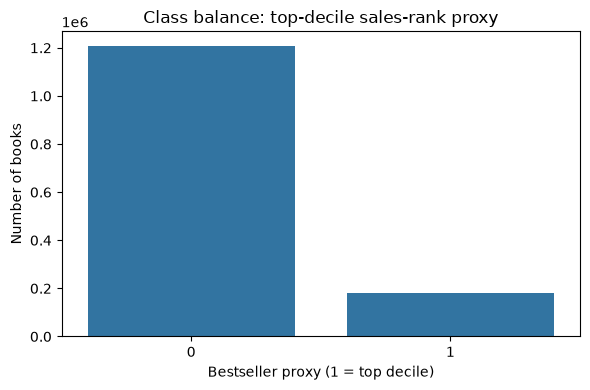

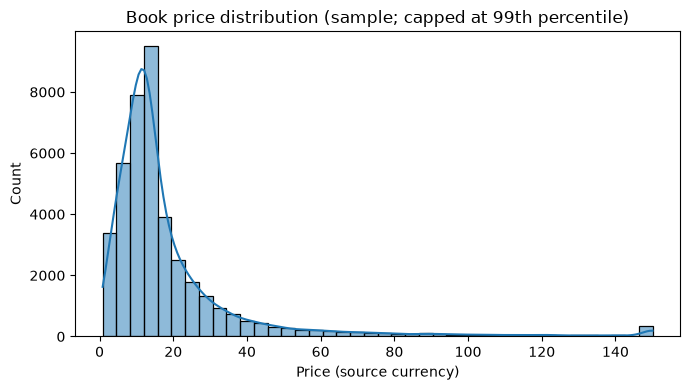

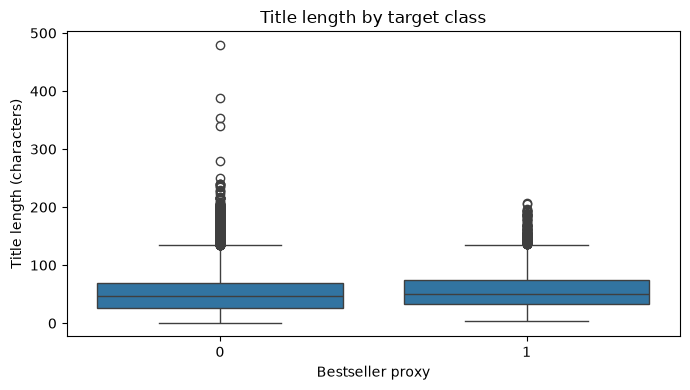

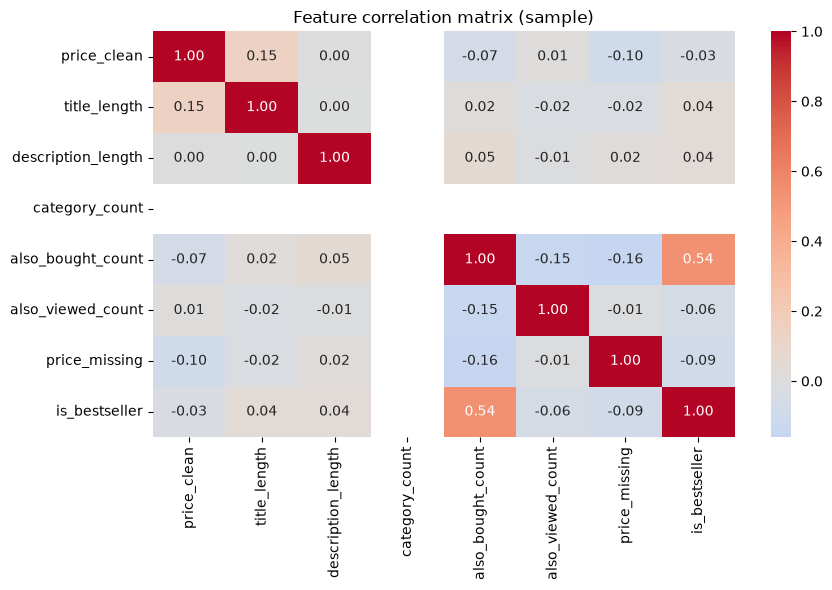

In [9]:
# Collect only small aggregate tables to the driver for plotting.
class_pd = features.groupBy("is_bestseller").count().orderBy("is_bestseller").toPandas()
plt.figure(figsize=(6, 4))
sns.barplot(data=class_pd, x="is_bestseller", y="count")
plt.title("Class balance: top-decile sales-rank proxy")
plt.xlabel("Bestseller proxy (1 = top decile)")
plt.ylabel("Number of books")
plt.tight_layout()
plt.show()

# Price distribution (sampled for plotting to keep driver memory controlled).
sample_pd = features.select("price_clean", "title_length", "description_length",
                            "also_bought_count", "also_viewed_count", "is_bestseller", "category_count", "price_missing") \
                    .sample(False, 0.03, seed=42).limit(50000).toPandas()
plt.figure(figsize=(7, 4))
sns.histplot(data=sample_pd, x="price_clean", bins=40, kde=True)
plt.title("Book price distribution (sample; capped at 99th percentile)")
plt.xlabel("Price (source currency)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=sample_pd, x="is_bestseller", y="title_length")
plt.title("Title length by target class")
plt.xlabel("Bestseller proxy")
plt.ylabel("Title length (characters)")
plt.tight_layout()
plt.show()

eda_corr = sample_pd[numeric_features + ["is_bestseller"]].corr(numeric_only=True)
plt.figure(figsize=(9, 6))
sns.heatmap(eda_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature correlation matrix (sample)")
plt.tight_layout()
plt.show()

## 7. Feature selection and train/validation/test split

In [10]:
# Select a compact set of numeric predictors based on availability, interpretability,
# and data quality. The sales-rank target source is intentionally excluded.
selected_features = [
    "price_clean", "title_length", "description_length", "category_count",
    "also_bought_count", "also_viewed_count", "price_missing"
]
print("Selected predictors:", selected_features)

# Convert the prepared, deduplicated modelling table to Pandas for NumPy training.
# Spark performed the data reading, cleaning, feature engineering, aggregation and EDA.
# A 2.37M-row table may be too large for a laptop; set MAX_MODEL_ROWS to a manageable
# stratified sample. Keep the full Spark EDA regardless of the modelling sample size.
MAX_MODEL_ROWS = 250_000
model_pd = features.select(selected_features + ["is_bestseller"]).sampleBy(
    "is_bestseller", fractions={0: 0.12, 1: 0.12}, seed=42
).limit(MAX_MODEL_ROWS).toPandas()

# Ensure both classes are represented and inspect target balance in modelling data.
model_pd = model_pd.replace([np.inf, -np.inf], np.nan).dropna()
model_pd["is_bestseller"] = model_pd["is_bestseller"].astype(int)
print(model_pd.shape)
print(model_pd["is_bestseller"].value_counts(normalize=True).rename("proportion"))

Selected predictors: ['price_clean', 'title_length', 'description_length', 'category_count', 'also_bought_count', 'also_viewed_count', 'price_missing']
(167134, 8)
is_bestseller
0    0.868722
1    0.131278
Name: proportion, dtype: float64


## 8. Prepare arrays without data leakage

In [11]:
# Stratified split using NumPy, avoiding a dependency on a pre-built classifier.
rng = np.random.default_rng(42)
y_all = model_pd["is_bestseller"].to_numpy(dtype=float)
X_all = model_pd[selected_features].to_numpy(dtype=float)

train_idx, val_idx, test_idx = [], [], []
for label in [0, 1]:
    idx = np.where(y_all == label)[0]
    rng.shuffle(idx)
    n = len(idx)
    n_train = int(0.70 * n)
    n_val = int(0.15 * n)
    train_idx.extend(idx[:n_train])
    val_idx.extend(idx[n_train:n_train+n_val])
    test_idx.extend(idx[n_train+n_val:])

train_idx, val_idx, test_idx = map(np.array, (train_idx, val_idx, test_idx))
rng.shuffle(train_idx); rng.shuffle(val_idx); rng.shuffle(test_idx)

X_train_raw, y_train = X_all[train_idx], y_all[train_idx]
X_val_raw, y_val = X_all[val_idx], y_all[val_idx]
X_test_raw, y_test = X_all[test_idx], y_all[test_idx]

# Standardisation parameters are learned from the training split only.
mu = X_train_raw.mean(axis=0)
sigma = X_train_raw.std(axis=0)
sigma[sigma == 0] = 1.0

X_train = (X_train_raw - mu) / sigma
X_val = (X_val_raw - mu) / sigma
X_test = (X_test_raw - mu) / sigma

print("Train/validation/test:", X_train.shape, X_val.shape, X_test.shape)
print("Positive class rates:", y_train.mean(), y_val.mean(), y_test.mean())

Train/validation/test: (116993, 7) (25069, 7) (25072, 7)
Positive class rates: 0.1312728111938321 0.13127767362080658 0.1313018506700702


## 9. Logistic Regression implemented from scratch

In [12]:
# Logistic Regression models P(y=1|x) with the sigmoid of a linear score.
# We implement the loss, gradient, and gradient-descent updates directly.
def sigmoid(z):
    # Clipping prevents overflow in exp for very large magnitudes.
    z = np.clip(z, -35, 35)
    return 1.0 / (1.0 + np.exp(-z))

def binary_cross_entropy(y, p):
    eps = 1e-12
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

class ScratchLogisticRegression:
    def __init__(self, learning_rate=0.05, epochs=800, l2=0.01):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.l2 = l2
        self.weights = None
        self.bias = 0.0
        self.loss_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features, dtype=float)
        self.bias = 0.0
        for epoch in range(self.epochs):
            # Forward pass: predicted probabilities.
            p = sigmoid(X @ self.weights + self.bias)
            # Gradient of binary cross-entropy plus L2 penalty on weights.
            error = p - y
            dw = (X.T @ error) / n_samples + self.l2 * self.weights
            db = np.mean(error)
            # Gradient descent update.
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
            if epoch % 10 == 0 or epoch == self.epochs - 1:
                p_now = sigmoid(X @ self.weights + self.bias)
                loss = binary_cross_entropy(y, p_now) + (self.l2 / 2) * np.sum(self.weights ** 2)
                self.loss_history.append(loss)
        return self

    def predict_proba(self, X):
        return sigmoid(X @ self.weights + self.bias)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

print("Scratch Logistic Regression class defined.")

Scratch Logistic Regression class defined.


## 10. Metrics and baseline

In [13]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

def evaluate_model(model, X, y, threshold=0.5, label="model"):
    prob = model.predict_proba(X)
    pred = (prob >= threshold).astype(int)
    result = {
        "model": label,
        "threshold": threshold,
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, prob),
        "pr_auc": average_precision_score(y, prob)
    }
    return result, prob, pred

# Majority-class baseline helps show whether the classifier improves on a trivial rule.
majority_class = int(np.bincount(y_train.astype(int)).argmax())
baseline_pred = np.full_like(y_test, majority_class, dtype=int)
print("Majority-class baseline accuracy:", accuracy_score(y_test, baseline_pred))
print("Positive-class baseline recall:", recall_score(y_test, baseline_pred, zero_division=0))

Majority-class baseline accuracy: 0.8686981493299298
Positive-class baseline recall: 0.0


## 11. Train baseline model and inspect convergence

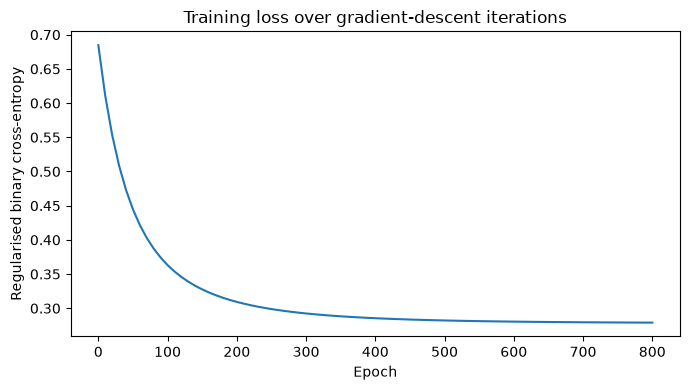

,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,baseline,0.5,0.888508,0.585223,0.517472,0.549266,0.871313,0.522667


In [14]:
baseline_model = ScratchLogisticRegression(learning_rate=0.05, epochs=800, l2=0.01)
baseline_model.fit(X_train, y_train)

plt.figure(figsize=(7, 4))
plt.plot(np.arange(len(baseline_model.loss_history)) * 10, baseline_model.loss_history)
plt.title("Training loss over gradient-descent iterations")
plt.xlabel("Epoch")
plt.ylabel("Regularised binary cross-entropy")
plt.tight_layout()
plt.show()

val_base, val_prob_base, val_pred_base = evaluate_model(
    baseline_model, X_val, y_val, threshold=0.5, label="baseline"
)
pd.DataFrame([val_base])

## 12. Retrain with alternative hyperparameters

In [15]:
# Compare a more conservative learning rate and stronger regularisation.
# Use validation PR-AUC/F1 to assess whether the change helps the positive class.
tuned_model = ScratchLogisticRegression(learning_rate=0.02, epochs=1200, l2=0.10)
tuned_model.fit(X_train, y_train)

val_tuned, val_prob_tuned, val_pred_tuned = evaluate_model(
    tuned_model, X_val, y_val, threshold=0.5, label="tuned"
)
comparison = pd.DataFrame([val_base, val_tuned])
display(comparison)

# Choose the model by validation PR-AUC; use validation data only for model selection.
chosen_model = tuned_model if val_tuned["pr_auc"] >= val_base["pr_auc"] else baseline_model
chosen_name = "tuned" if chosen_model is tuned_model else "baseline"
print("Chosen model based on validation PR-AUC:", chosen_name)

,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,baseline,0.5,0.888508,0.585223,0.517472,0.549266,0.871313,0.522667
1,tuned,0.5,0.868762,0.666667,0.000608,0.001214,0.869611,0.520098


Chosen model based on validation PR-AUC: baseline


## 13. Select a decision threshold using validation data

In [16]:
# For imbalanced classes, 0.5 may not be the best operating threshold.
# Choose the threshold that maximises validation F1, then freeze it before test evaluation.
val_prob = chosen_model.predict_proba(X_val)
thresholds = np.linspace(0.10, 0.90, 81)
threshold_scores = []
for threshold in thresholds:
    pred = (val_prob >= threshold).astype(int)
    threshold_scores.append(f1_score(y_val, pred, zero_division=0))
best_threshold = float(thresholds[int(np.argmax(threshold_scores))])
print("Selected validation threshold:", best_threshold)
print("Validation F1 at selected threshold:", max(threshold_scores))

Selected validation threshold: 0.25
Validation F1 at selected threshold: 0.5644645711241343


## 14. Final test evaluation

,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,baseline,0.25,0.870932,0.506641,0.648846,0.568993,0.874467,0.531852


                precision    recall  f1-score   support

Not top-decile       0.94      0.90      0.92     21780
    Top-decile       0.51      0.65      0.57      3292

      accuracy                           0.87     25072
     macro avg       0.73      0.78      0.75     25072
  weighted avg       0.89      0.87      0.88     25072



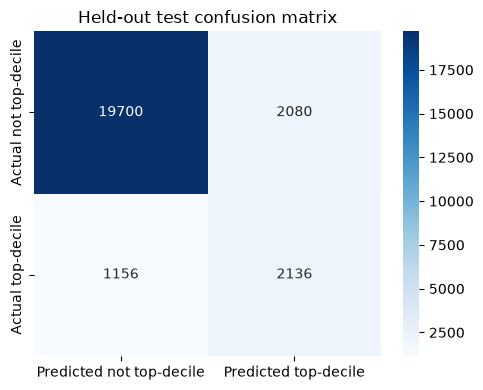

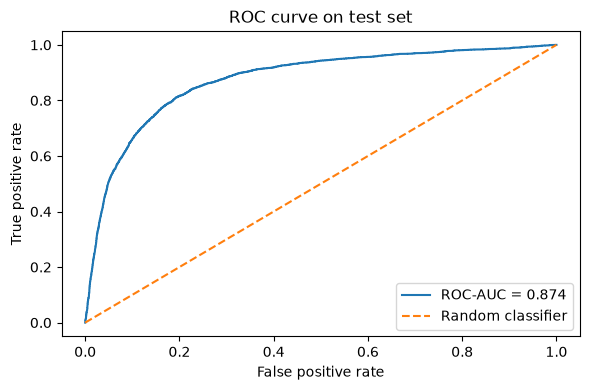

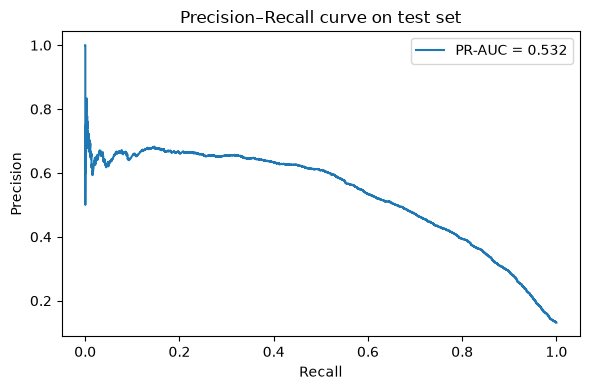

In [17]:
# The test set is held back until final evaluation to reduce optimistic reporting.
test_result, test_prob, test_pred = evaluate_model(
    chosen_model, X_test, y_test, threshold=best_threshold, label=chosen_name
)
display(pd.DataFrame([test_result]))
print(classification_report(y_test, test_pred, target_names=["Not top-decile", "Top-decile"], zero_division=0))

cm = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted not top-decile", "Predicted top-decile"],
            yticklabels=["Actual not top-decile", "Actual top-decile"])
plt.title("Held-out test confusion matrix")
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_test, test_prob)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"ROC-AUC = {test_result['roc_auc']:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve on test set")
plt.legend()
plt.tight_layout()
plt.show()

precision, recall, _ = precision_recall_curve(y_test, test_prob)
plt.figure(figsize=(6, 4))
plt.plot(recall, precision, label=f"PR-AUC = {test_result['pr_auc']:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall curve on test set")
plt.legend()
plt.tight_layout()
plt.show()

## 15. Interpret coefficients

,feature,standardised_coefficient,absolute_effect
4,also_bought_count,1.103865,1.103865
1,title_length,0.115483,0.115483
6,price_missing,-0.111353,0.111353
2,description_length,0.034881,0.034881
0,price_clean,-0.015643,0.015643
5,also_viewed_count,0.013339,0.013339
3,category_count,0.000000,0.000000


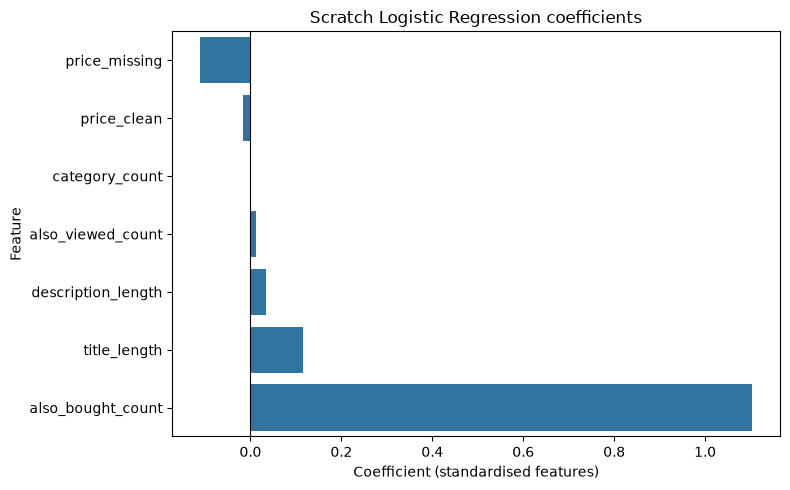

In [18]:
# Positive coefficients increase the model's log-odds of belonging to the top-decile
# rank group; negative coefficients decrease them, holding other features constant.
coef_table = pd.DataFrame({
    "feature": selected_features,
    "standardised_coefficient": chosen_model.weights
})
coef_table["absolute_effect"] = coef_table["standardised_coefficient"].abs()
coef_table = coef_table.sort_values("absolute_effect", ascending=False)
display(coef_table)

plt.figure(figsize=(8, 5))
plot_coef = coef_table.sort_values("standardised_coefficient")
sns.barplot(data=plot_coef, x="standardised_coefficient", y="feature")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Scratch Logistic Regression coefficients")
plt.xlabel("Coefficient (standardised features)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 16. Save outputs for the report

Run this cell after the notebook completes. It writes summary tables and model details to a local `outputs` directory. Review the saved figures and insert actual values into the report; do not report unexecuted or hypothetical scores.

**Interpretation checklist**
- Compare test metrics against the majority-class baseline.
- Discuss precision and recall together: false positives waste marketing effort, while false negatives may miss promising books.
- Use ROC-AUC for ranking discrimination and PR-AUC for performance on the positive class.
- Mention that the label is a top-decile Amazon sales-rank proxy, not an official bestseller list.
- State the exact row counts after each cleaning stage and the actual modelling sample size.

In [19]:
from pathlib import Path
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

pd.DataFrame([test_result]).to_csv(OUT / "test_metrics.csv", index=False)
comparison.to_csv(OUT / "validation_model_comparison.csv", index=False)
coef_table.to_csv(OUT / "model_coefficients.csv", index=False)

with open(OUT / "model_summary.txt", "w", encoding="utf-8") as f:
    f.write("Dataset: Amazon Books product metadata (McAuley Lab / UCSD)\\n")
    f.write(f"Valid ranked records before feature cleaning: {ranked.count()}\\n")
    f.write(f"Rank threshold for top-decile proxy: {rank_threshold}\\n")
    f.write(f"Final feature rows: {features.count()}\\n")
    f.write(f"Modelling sample rows: {len(model_pd)}\\n")
    f.write(f"Selected model: {chosen_name}\\n")
    f.write(f"Selected threshold: {best_threshold}\\n")
    f.write(f"Selected features: {selected_features}\\n")
    f.write(f"Test metrics: {test_result}\\n")

print("Saved outputs to:", OUT.resolve())

Saved outputs to: C:\Users\Student\Documents\PDAN\Part1\outputs


## References

McAuley, J., Targett, C., Shi, J. and van den Hengel, A. (2015). *Image-based recommendations on styles and substitutes*. Proceedings of the 38th International ACM SIGIR Conference on Research and Development in Information Retrieval.

McAuley Lab. (n.d.). *Amazon product data: metadata and reviews*. University of California San Diego. https://mcauleylab.ucsd.edu/public_datasets/data/amazon/datasets.html

Dataset file: *meta_Books.json.gz*. https://snap.stanford.edu/data/amazon/productGraph/categoryFiles/meta_Books.json.gz

**Reproducibility note:** Record the date you downloaded the dataset, the final row counts printed by this notebook, your local Python/PySpark versions, and any adjustments made to the schema or sample size.